# Bài tập lớn Học máy (HK261) — Phân loại cảm xúc UIT-VSFC (3 nhãn)

- **Môn học:** Học máy — Học kỳ I, năm học 2026-2027
- **Đơn vị:** Khoa Khoa học và Kỹ thuật Máy tính, Trường Đại học Bách Khoa — ĐHQG-HCM
- **Đề tài:** Bài 2 — Học máy với dữ liệu văn bản (Phân loại cảm xúc: Tiêu cực, Trung tính, Tích cực)
- **Tập dữ liệu:** UIT-VSFC (`uitnlp/vietnamese_students_feedback`)
- **Sinh viên thực hiện:** Võ Lê Thanh Bình — MSSV: `2352127`
- **Repository GitHub:** https://github.com/volethanhbinh/ml-uit-vsfc.git

> **Lưu ý vận hành trên Google Colab:** `Runtime -> Run all`. Notebook tự động cài đặt thư viện, clone repository từ GitHub và tải dữ liệu công khai (không mount Google Drive).


## 1. Cài đặt thư viện, Clone Repository & Thiết lập môi trường


In [1]:
import os
import sys
import subprocess

REPO_URL = "https://github.com/volethanhbinh/ml-uit-vsfc.git"
REPO_DIR = "ml-uit-vsfc"

# Tự động định vị thư mục gốc dự án hoặc clone từ GitHub nếu chạy trên Colab sạch
if os.path.isdir("modules") and os.path.isfile("requirements.txt"):
    PROJECT_ROOT = os.path.abspath(".")
elif os.path.isdir(os.path.join(REPO_DIR, "modules")):
    PROJECT_ROOT = os.path.abspath(REPO_DIR)
    os.chdir(PROJECT_ROOT)
else:
    print(f"Đang clone repository từ {REPO_URL}...")
    subprocess.run(["git", "clone", REPO_URL], check=True)
    PROJECT_ROOT = os.path.abspath(REPO_DIR)
    os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print(f"Thư mục làm việc hiện tại: {os.getcwd()}")

Đang clone repository từ https://github.com/volethanhbinh/ml-uit-vsfc.git...
Thư mục làm việc hiện tại: /content/ml-uit-vsfc


In [2]:
# Cài đặt các thư viện cần thiết (chạy êm trên Google Colab)
!pip install -q datasets pyarrow pyvi transformers accelerate scikit-learn seaborn tqdm

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
from IPython.display import display

from modules.data_loader import load_uit_vsfc, LABEL_MAP
from modules.eda import run_full_eda
from modules.preprocessing import VietnameseTextPreprocessor, get_ablation_configs
from modules.feature_extraction import (
    TraditionalFeatureExtractor,
    extract_and_save_phobert_embeddings,
    load_embeddings,
)
from modules.models import (
    set_all_seeds,
    train_and_evaluate_traditional,
    run_traditional_experiments,
    run_hybrid_experiments,
    finetune_phobert_end_to_end,
)
from modules.evaluation import (
    evaluate_predictions,
    plot_confusion_matrix,
    plot_model_comparison,
    perform_error_analysis,
)

SEED = 42
set_all_seeds(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## 2. Tải dữ liệu UIT-VSFC & Phân tích khám phá dữ liệu (EDA)


In [4]:
train_df, val_df, test_df = load_uit_vsfc()
print(f"Kích thước tập Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

display(train_df.head(5))

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  475kB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 63.3kB            

default/validation/0000.parquet: downloading bytes:           |  0.00B            

default/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  134kB            

default/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Kích thước tập Train: 11,426 | Val: 1,583 | Test: 3,166


,text,label,label_name
0,slide giáo trình đầy đủ .,2,Tích cực
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,Tích cực
2,đi học đầy đủ full điểm chuyên cần .,0,Tiêu cực
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,Tiêu cực
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,Tích cực


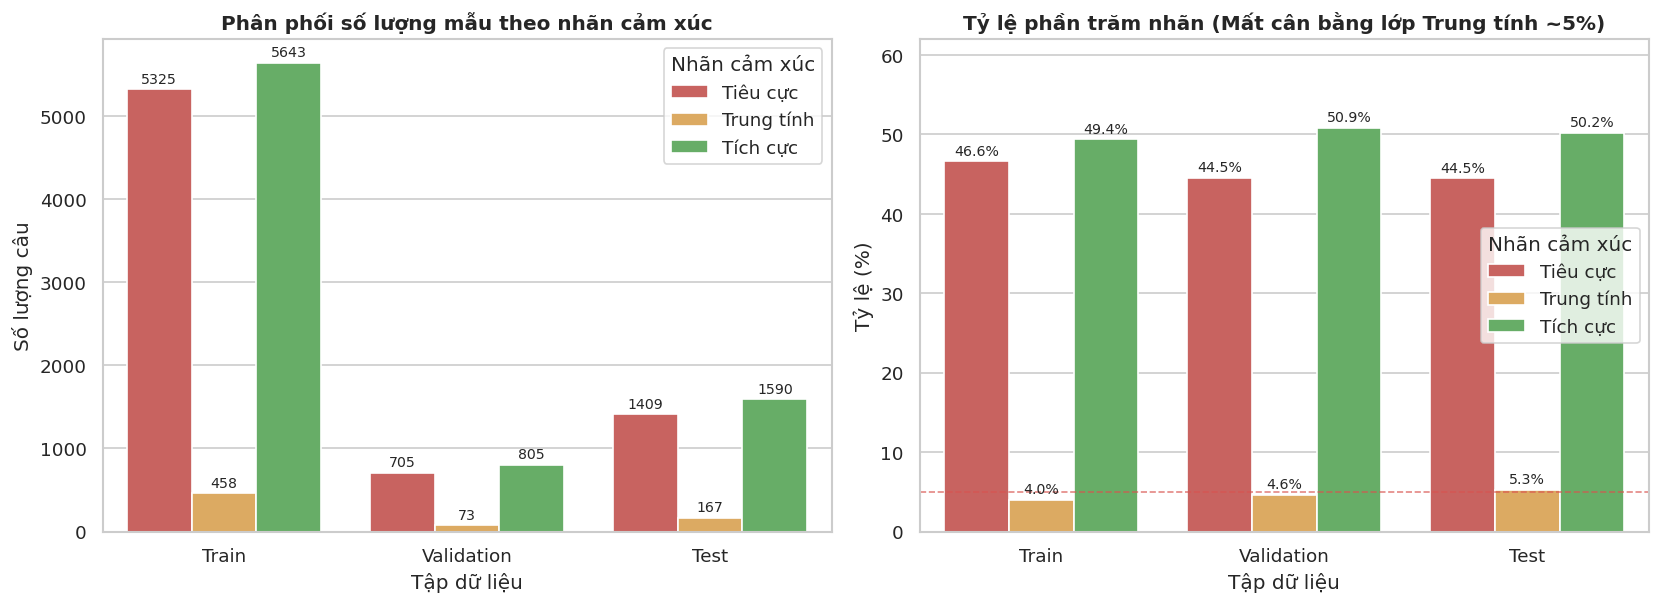

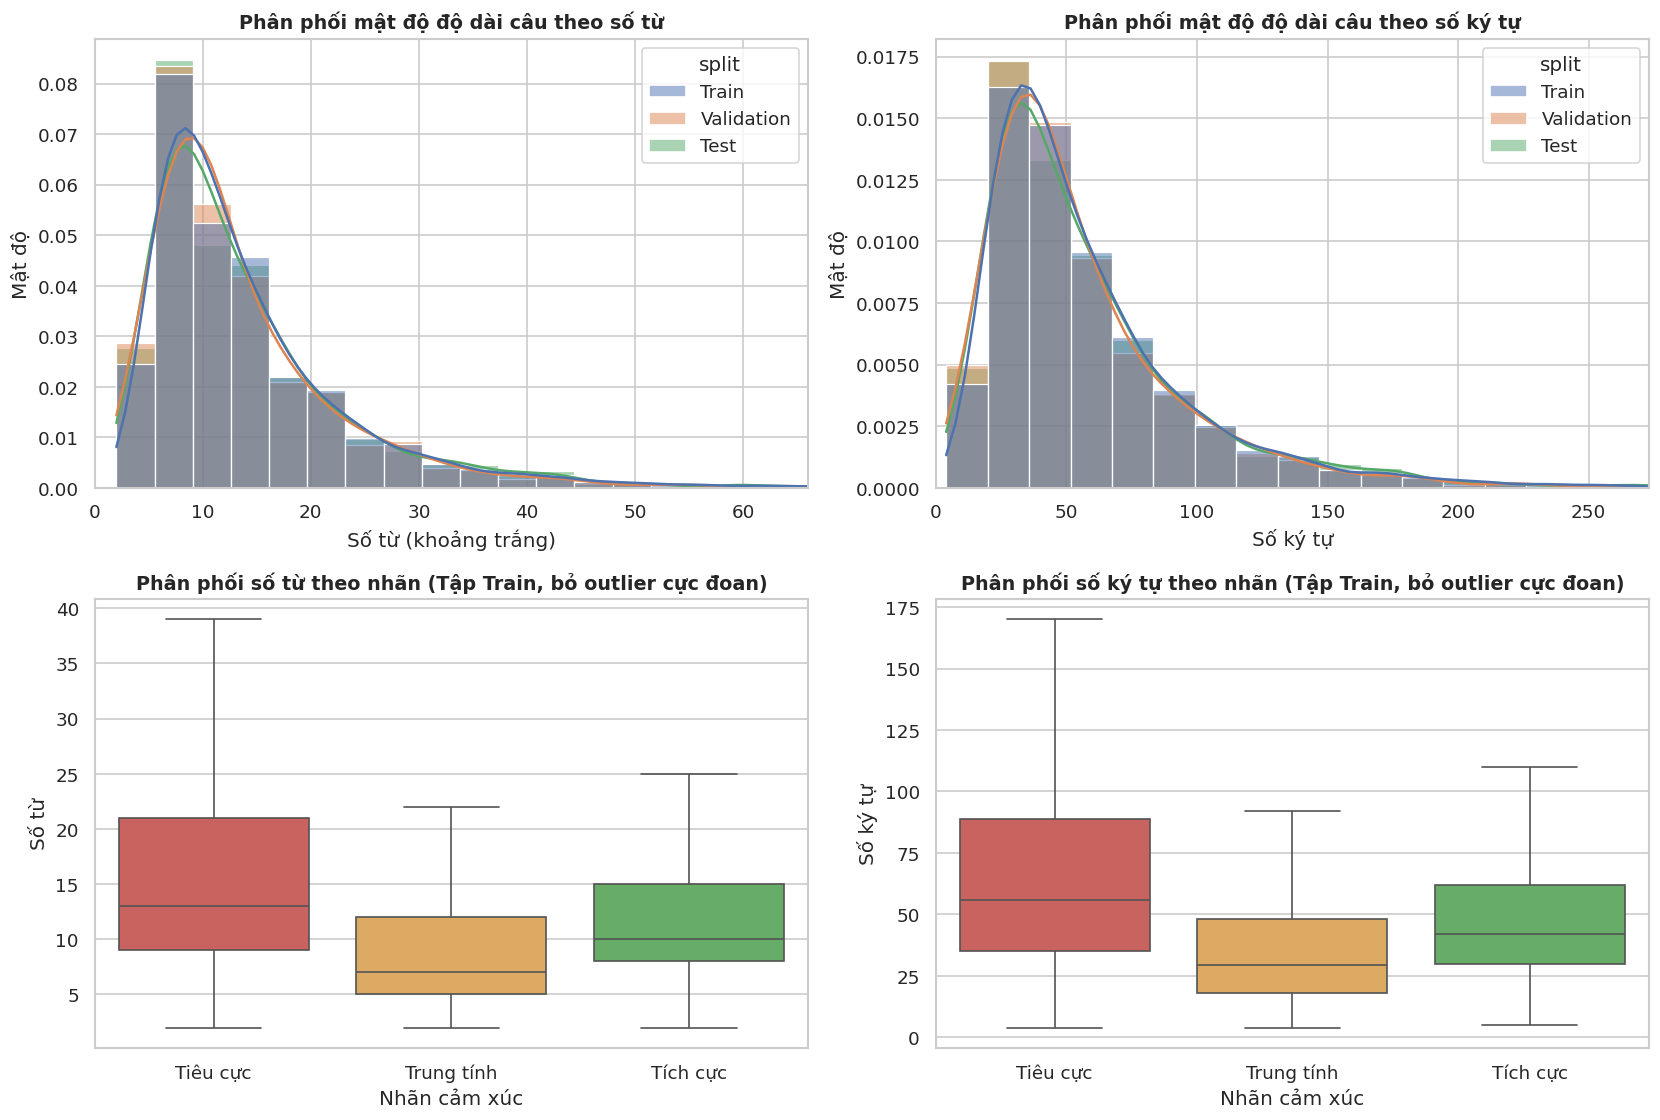

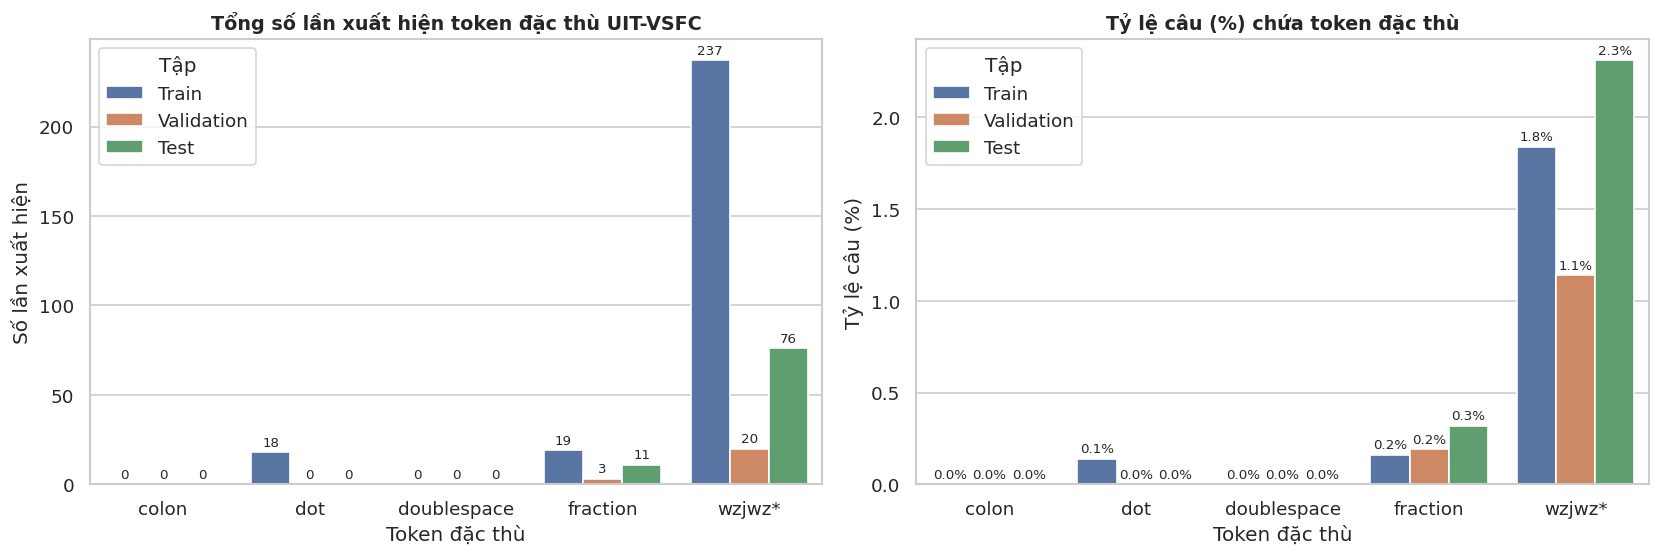

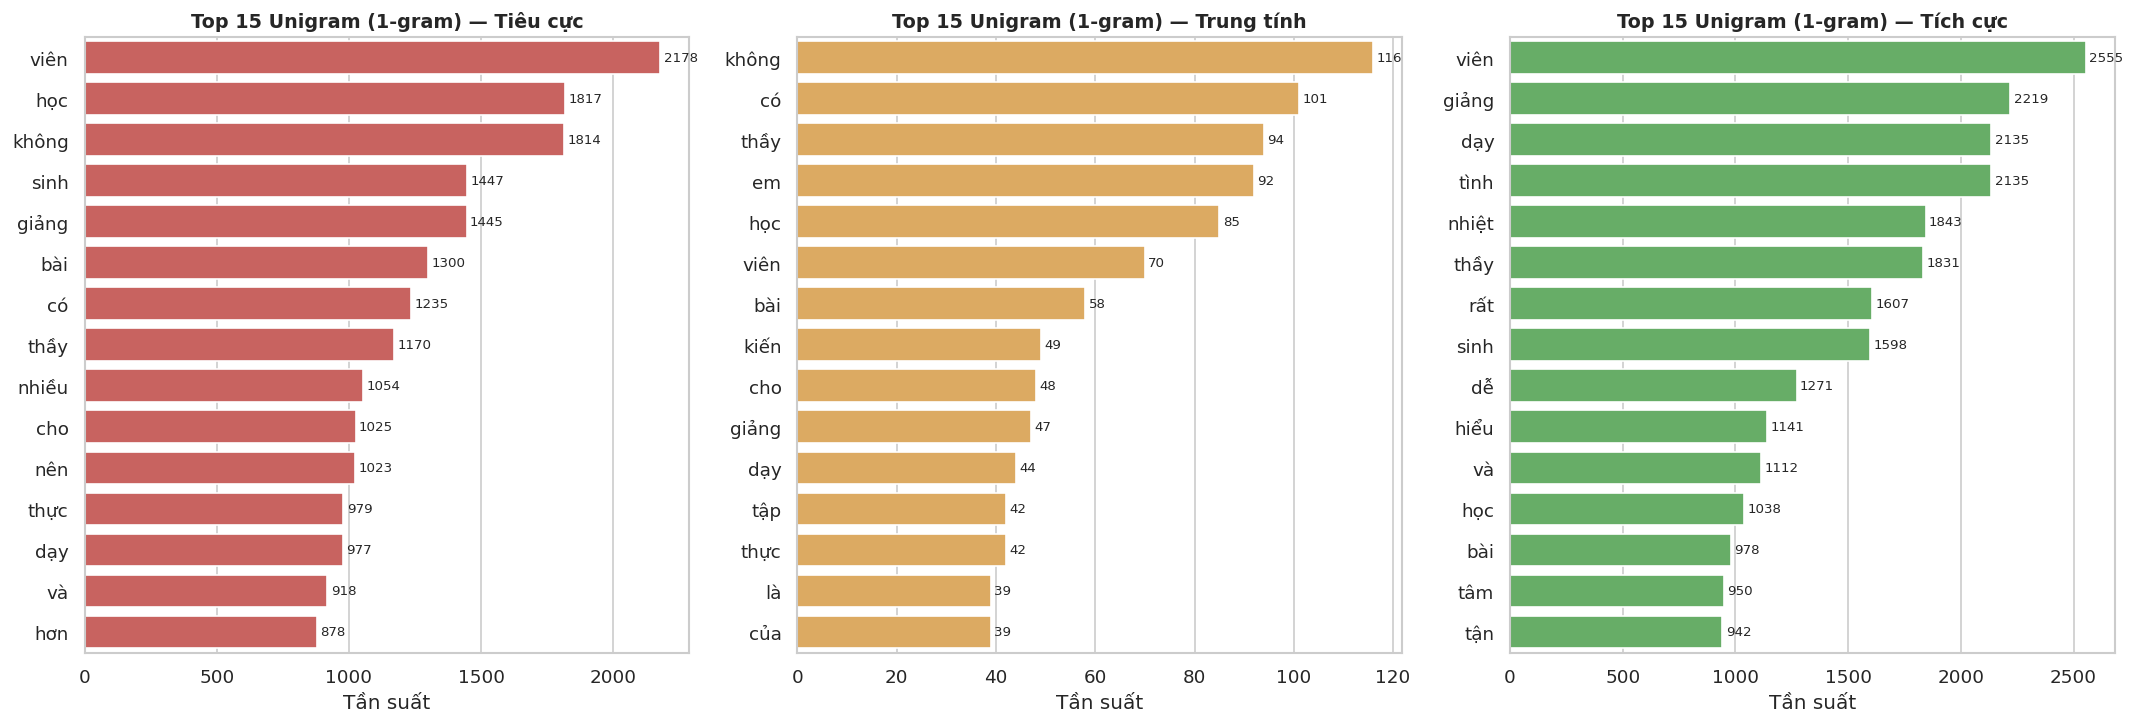

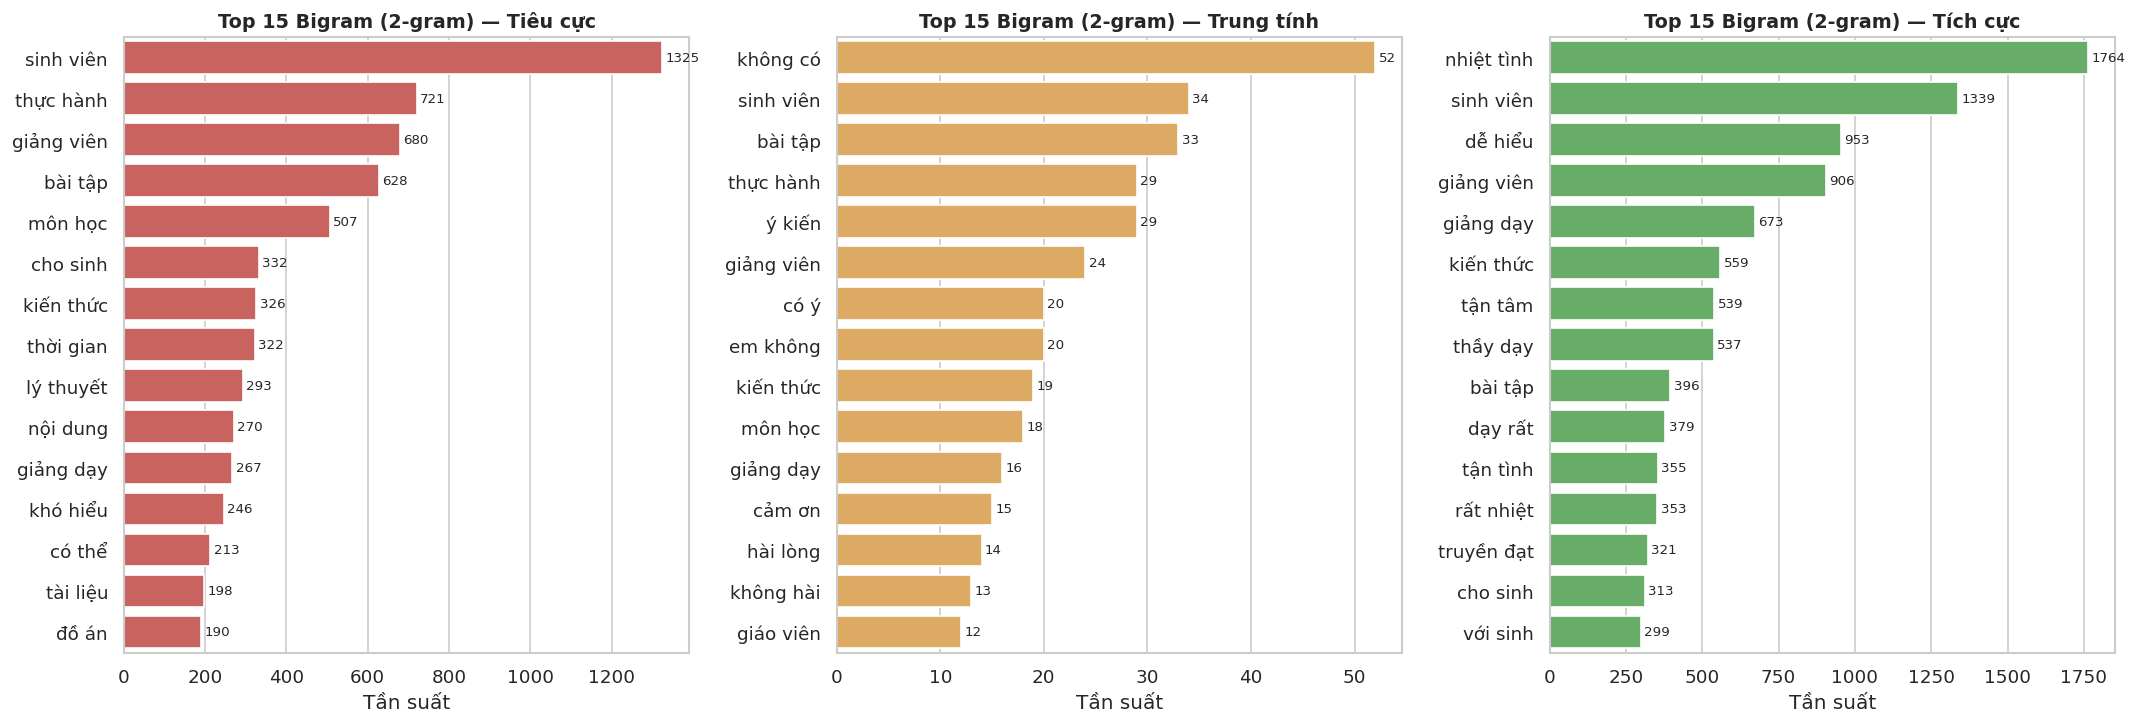

=== BẢNG TỔNG QUAN DỮ LIỆU ===


,Tập dữ liệu,Số mẫu,Thiếu text,Mẫu rỗng,Thiếu label,Trùng text,"Trùng (text, label)",Tiêu cực (SL),Tiêu cực (%),Trung tính (SL),Trung tính (%),Tích cực (SL),Tích cực (%)
0,Train,11426,0,0,0,1,0,5325,46.60,458,4.01,5643,49.39
1,Validation,1583,0,0,0,0,0,705,44.54,73,4.61,805,50.85
2,Test,3166,0,0,0,0,0,1409,44.50,167,5.27,1590,50.22


Trùng lặp câu giữa Train & Val: 0 | giữa Train & Test: 0

=== THỐNG KÊ ĐỘ DÀI CÂU ===


,Tập,Đơn vị,Mean,Std,Min,Median (50%),P95,P99,Max
0,Train,Số từ (Word),14.31,10.09,2,11.0,33.0,52.0,159
1,Train,Số ký tự (Char),59.08,43.08,4,47.0,141.0,218.8,660
2,Validation,Số từ (Word),13.67,9.91,2,11.0,31.0,46.0,161
3,Validation,Số ký tự (Char),56.36,42.75,4,45.0,132.0,196.2,718
4,Test,Số từ (Word),14.22,10.24,2,11.0,34.0,52.3,98
5,Test,Số ký tự (Char),58.84,44.12,4,46.0,147.0,221.3,411



=== TẦN SUẤT TOKEN ĐẶC THÙ UIT-VSFC ===


,Tập,Token đặc thù,Tổng số lần xuất hiện,Số câu chứa token,Tỷ lệ câu chứa (%)
0,Train,colon,0,0,0.00
1,Train,dot,18,16,0.14
2,Train,doublespace,0,0,0.00
3,Train,fraction,19,18,0.16
4,Train,wzjwz*,237,210,1.84
5,Validation,colon,0,0,0.00
6,Validation,dot,0,0,0.00
7,Validation,doublespace,0,0,0.00
8,Validation,fraction,3,3,0.19
9,Validation,wzjwz*,20,18,1.14


In [5]:
eda_results = run_full_eda(
    train_df,
    val_df,
    test_df,
    save_dir="reports/figures",
    show=True,
)

print("=== BẢNG TỔNG QUAN DỮ LIỆU ===")
display(eda_results["overview"])
print(
    f"Trùng lặp câu giữa Train & Val: {eda_results['overview'].attrs['train_val_overlap']} | "
    f"giữa Train & Test: {eda_results['overview'].attrs['train_test_overlap']}"
)

print("\n=== THỐNG KÊ ĐỘ DÀI CÂU ===")
display(eda_results["length_stats"])

print("\n=== TẦN SUẤT TOKEN ĐẶC THÙ UIT-VSFC ===")
display(eda_results["special_tokens"])

## 3. Thí nghiệm 1 — Khảo sát cấu hình Tiền xử lý (Preprocessing Ablation Study)

So sánh 4 cấu hình tiền xử lý kết hợp bật/tắt `word_segment` (`pyvi.ViTokenizer`) và `remove_stopwords` (với danh sách giữ lại từ phủ định/chuyển ý: *không, chưa, chẳng, nhưng, tuy, hơi, quá, rất...*), đánh giá bằng đặc trưng `TF-IDF (1,2)` với `LogisticRegression` và `LinearSVC` (`class_weight='balanced'`).


In [6]:
ablation_configs = get_ablation_configs()
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

exp1_frames = []
preprocessed_cache = {}

for cfg_name, preprocessor in ablation_configs.items():
    print(f"\n--- Đang xử lý cấu hình: {cfg_name} ---")
    tr_clean = preprocessor.transform(train_df["text"])
    va_clean = preprocessor.transform(val_df["text"])
    te_clean = preprocessor.transform(test_df["text"])
    preprocessed_cache[cfg_name] = (tr_clean, va_clean, te_clean)

    vec = TraditionalFeatureExtractor(
        method="tfidf",
        ngram_range=(1, 2),
        max_features=20000,
        min_df=2,
    )
    X_tr = vec.fit_transform(tr_clean)
    X_va = vec.transform(va_clean)
    X_te = vec.transform(te_clean)

    df_res, _ = train_and_evaluate_traditional(
        X_tr,
        y_train,
        X_va,
        y_val,
        X_te,
        y_test,
        feature_label=f"{cfg_name} | TF-IDF(1,2)",
        class_weight="balanced",
        random_state=SEED,
        verbose=False,
    )
    exp1_frames.append(df_res)

exp1_df = pd.concat(exp1_frames, ignore_index=True).sort_values(by="Macro F1", ascending=False)
print("=== KẾT QUẢ THÍ NGHIỆM 1 (SẮP XẾP THEO TEST MACRO F1) ===")
display(exp1_df)

# Chọn cấu hình tiền xử lý tốt nhất theo Val Macro F1 (tránh data leakage từ tập Test)
best_exp1_row = exp1_df.sort_values(by="Val Macro F1", ascending=False).iloc[0]
best_cfg_name = best_exp1_row["Mô hình"].split(" | TF-IDF")[0]
print(f"\n>>> Cấu hình tiền xử lý tốt nhất (theo Val Macro F1): {best_cfg_name}")
tr_best_clean, va_best_clean, te_best_clean = preprocessed_cache[best_cfg_name]


--- Đang xử lý cấu hình: C1: NoSeg + KeepSW ---

--- Đang xử lý cấu hình: C2: NoSeg + RemoveSW ---

--- Đang xử lý cấu hình: C3: WordSeg + KeepSW ---

--- Đang xử lý cấu hình: C4: WordSeg + RemoveSW ---
=== KẾT QUẢ THÍ NGHIỆM 1 (SẮP XẾP THEO TEST MACRO F1) ===


,Mô hình,Split,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 (Tiêu cực),F1 (Trung tính),F1 (Tích cực),Val Macro F1,Nhóm
8,"C3: WordSeg + KeepSW | TF-IDF(1,2) + LinearSVC...",Test,0.8945,0.7591,0.7225,0.7359,0.8900,0.9152,0.3701,0.9222,0.7681,Truyền thống
2,"C1: NoSeg + KeepSW | TF-IDF(1,2) + LinearSVC (...",Test,0.8929,0.7531,0.7161,0.7293,0.8880,0.9143,0.3525,0.9210,0.7714,Truyền thống
7,"C3: WordSeg + KeepSW | TF-IDF(1,2) + LogisticR...",Test,0.8705,0.7118,0.7358,0.7207,0.8756,0.8975,0.3538,0.9109,0.7535,Truyền thống
1,"C1: NoSeg + KeepSW | TF-IDF(1,2) + LogisticReg...",Test,0.8654,0.7063,0.7306,0.7149,0.8710,0.8905,0.3452,0.9090,0.7523,Truyền thống
5,"C2: NoSeg + RemoveSW | TF-IDF(1,2) + LinearSVC...",Test,0.8765,0.7296,0.7041,0.7140,0.8727,0.8934,0.3379,0.9105,0.7342,Truyền thống
11,"C4: WordSeg + RemoveSW | TF-IDF(1,2) + LinearS...",Test,0.8677,0.7103,0.6996,0.7042,0.8657,0.8863,0.3215,0.9047,0.7305,Truyền thống
10,"C4: WordSeg + RemoveSW | TF-IDF(1,2) + Logisti...",Test,0.8427,0.6835,0.7192,0.6931,0.8538,0.8670,0.3135,0.8987,0.7136,Truyền thống
6,"C3: WordSeg + KeepSW | TF-IDF(1,2) + Multinomi...",Test,0.8402,0.6824,0.7195,0.6916,0.8520,0.8678,0.3124,0.8946,0.7332,Truyền thống
4,"C2: NoSeg + RemoveSW | TF-IDF(1,2) + LogisticR...",Test,0.8380,0.6781,0.7107,0.6870,0.8484,0.8623,0.3056,0.8931,0.7197,Truyền thống
0,"C1: NoSeg + KeepSW | TF-IDF(1,2) + Multinomial...",Test,0.8253,0.6662,0.6964,0.6745,0.8355,0.8473,0.2941,0.8819,0.7168,Truyền thống



>>> Cấu hình tiền xử lý tốt nhất (theo Val Macro F1): C1: NoSeg + KeepSW


## 4. Thí nghiệm 2 — Pipeline Machine Learning truyền thống (BoW / TF-IDF × NB / LR / Linear SVM)

Đánh giá toàn diện sự kết hợp giữa:
- **Biểu diễn:** `BoW (1,1)`, `TF-IDF (1,1)`, `TF-IDF (1,2)`
- **Mô hình:** `MultinomialNB`, `LogisticRegression`, `LinearSVC`
- **Xử lý mất cân bằng:** So sánh `class_weight=None` và `class_weight='balanced'`


In [7]:
exp2_df, exp2_artifacts = run_traditional_experiments(
    train_texts=tr_best_clean,
    y_train=y_train,
    val_texts=va_best_clean,
    y_val=y_val,
    test_texts=te_best_clean,
    y_test=y_test,
    class_weights=(None, "balanced"),
    random_state=SEED,
    verbose=False,
)

exp2_sorted = exp2_df.sort_values(by="Macro F1", ascending=False).reset_index(drop=True)
print("=== KẾT QUẢ THÍ NGHIỆM 2 — PIPELINE ML TRUYỀN THỐNG ===")
display(exp2_sorted)

best_trad_name = exp2_sorted.iloc[0]["Mô hình"]
print(f"\n>>> Báo cáo chi tiết mô hình ML truyền thống tốt nhất: {best_trad_name}")
evaluate_predictions(
    y_test,
    exp2_artifacts[best_trad_name]["test_pred"],
    model_name=best_trad_name,
    split_name="Test",
    verbose=True,
)

=== KẾT QUẢ THÍ NGHIỆM 2 — PIPELINE ML TRUYỀN THỐNG ===


,Mô hình,Split,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 (Tiêu cực),F1 (Trung tính),F1 (Tích cực),Val Macro F1,Nhóm
0,"TF-IDF (1,1) + LinearSVC (cw=balanced)",Test,0.8759,0.7331,0.7534,0.7417,0.8787,0.8967,0.4173,0.9112,0.7619,Truyền thống
1,"BoW (1,1) + LinearSVC (cw=balanced)",Test,0.8702,0.7279,0.7468,0.7362,0.8728,0.8866,0.4130,0.9089,0.7514,Truyền thống
2,"TF-IDF (1,2) + LinearSVC (cw=balanced)",Test,0.8929,0.7531,0.7161,0.7293,0.8880,0.9143,0.3525,0.9210,0.7714,Truyền thống
3,"TF-IDF (1,2) + LogisticRegression (cw=balanced)",Test,0.8654,0.7063,0.7306,0.7149,0.8710,0.8905,0.3452,0.9090,0.7523,Truyền thống
4,"BoW (1,1) + LogisticRegression (cw=balanced)",Test,0.8468,0.7011,0.7604,0.7143,0.8609,0.8710,0.3683,0.9038,0.7395,Truyền thống
5,"BoW (1,1) + LogisticRegression (cw=none)",Test,0.8850,0.7711,0.6922,0.7125,0.8765,0.9020,0.3237,0.9120,0.7437,Truyền thống
6,"BoW (1,1) + LinearSVC (cw=none)",Test,0.8806,0.7621,0.6923,0.7120,0.8728,0.8976,0.3306,0.9078,0.7275,Truyền thống
7,"TF-IDF (1,1) + LogisticRegression (cw=balanced)",Test,0.8377,0.6971,0.7649,0.7085,0.8554,0.8643,0.3620,0.8993,0.7146,Truyền thống
8,"TF-IDF (1,2) + LinearSVC (cw=none)",Test,0.8964,0.8085,0.6848,0.7050,0.8845,0.9138,0.2791,0.9221,0.7530,Truyền thống
9,"TF-IDF (1,1) + LinearSVC (cw=none)",Test,0.8850,0.7917,0.6785,0.6987,0.8738,0.9032,0.2831,0.9097,0.7088,Truyền thống



>>> Báo cáo chi tiết mô hình ML truyền thống tốt nhất: TF-IDF (1,1) + LinearSVC (cw=balanced)

=== [Test] TF-IDF (1,1) + LinearSVC (cw=balanced) ===
Accuracy: 0.8759 | Macro Precision: 0.7331 | Macro Recall: 0.7534 | Macro F1: 0.7417 | Weighted F1: 0.8787
              precision    recall  f1-score   support

    Tiêu cực     0.8852    0.9084    0.8967      1409
  Trung tính     0.3812    0.4611    0.4173       167
    Tích cực     0.9328    0.8906    0.9112      1590

    accuracy                         0.8759      3166
   macro avg     0.7331    0.7534    0.7417      3166
weighted avg     0.8825    0.8759    0.8787      3166



{'Mô hình': 'TF-IDF (1,1) + LinearSVC (cw=balanced)',
 'Split': 'Test',
 'Accuracy': 0.8759,
 'Macro Precision': 0.7331,
 'Macro Recall': 0.7534,
 'Macro F1': 0.7417,
 'Weighted F1': 0.8787,
 'F1 (Tiêu cực)': 0.8967,
 'F1 (Trung tính)': 0.4173,
 'F1 (Tích cực)': 0.9112}

## 5. Thí nghiệm 3 — Trích xuất PhoBERT Embeddings (`.npy`) & Pipeline Lai

1. Làm sạch token kỹ thuật UIT-VSFC (`colon`, `dot`, `doublespace`, `fraction`, `wzjwz...`) nhưng giữ nguyên chữ hoa/dấu câu và tách từ bằng `pyvi.ViTokenizer`.
2. Dùng `vinai/phobert-base-v2` (Mean Pooling với `attention_mask`, `max_length=128`, FP16 trên GPU) để trích xuất và lưu thành `features/phobert_train.npy`, `features/phobert_val.npy`, `features/phobert_test.npy`.
3. Đọc trực tiếp từ các file `.npy` thông qua `load_embeddings()` và huấn luyện `LogisticRegression`, `LinearSVC`, `MLP (256-64)`.


In [8]:
# Tiền xử lý nhẹ cho PhoBERT: chỉ làm sạch token nhiễu UIT-VSFC, giữ dấu câu & hoa/thường để bảo toàn ngữ cảnh
phobert_prep = VietnameseTextPreprocessor(
    lowercase=False,
    clean_special_tokens=True,
    remove_punctuation=False,
    word_segment=True,
    remove_stopwords=False,
)

tr_phobert_texts = phobert_prep.transform(train_df["text"])
va_phobert_texts = phobert_prep.transform(val_df["text"])
te_phobert_texts = phobert_prep.transform(test_df["text"])

# word_segment=False vì đã tách từ ở bước phobert_prep phía trên
extract_and_save_phobert_embeddings(
    train_texts=tr_phobert_texts,
    val_texts=va_phobert_texts,
    test_texts=te_phobert_texts,
    output_dir="features",
    batch_size=64,
    max_length=128,
    use_fp16=True,
    word_segment=False,
    force_recompute=False,
)

# Đọc lại trực tiếp từ features/*.npy
X_train_emb, X_val_emb, X_test_emb = load_embeddings("features")
print(f"Đã nạp embeddings: Train={X_train_emb.shape}, Val={X_val_emb.shape}, Test={X_test_emb.shape}")

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

PhoBERT Val:   0%|          | 0/25 [00:00<?, ?it/s]

PhoBERT Test:   0%|          | 0/50 [00:00<?, ?it/s]

[PhoBERT] Đã lưu thành công:
  - features/phobert_train.npy: (11426, 768) (float32)
  - features/phobert_val.npy: (1583, 768) (float32)
  - features/phobert_test.npy: (3166, 768) (float32)
Đã nạp embeddings: Train=(11426, 768), Val=(1583, 768), Test=(3166, 768)


In [9]:
exp3_df, exp3_artifacts = run_hybrid_experiments(
    X_train=X_train_emb,
    y_train=y_train,
    X_val=X_val_emb,
    y_val=y_val,
    X_test=X_test_emb,
    y_test=y_test,
    class_weights=(None, "balanced"),
    random_state=SEED,
    verbose=True,
)

exp3_sorted = exp3_df.sort_values(by="Macro F1", ascending=False).reset_index(drop=True)
print("=== KẾT QUẢ THÍ NGHIỆM 3 — PIPELINE LAI (PHOBERT .NPY) ===")
display(exp3_sorted)


=== [Test] PhoBERT (.npy) + LogisticRegression (cw=none) ===
Accuracy: 0.8955 | Macro Precision: 0.7623 | Macro Recall: 0.7365 | Macro F1: 0.7474 | Weighted F1: 0.8925
              precision    recall  f1-score   support

    Tiêu cực     0.9161    0.9219    0.9190      1409
  Trung tính     0.4580    0.3593    0.4027       167
    Tích cực     0.9128    0.9283    0.9205      1590

    accuracy                         0.8955      3166
   macro avg     0.7623    0.7365    0.7474      3166
weighted avg     0.8903    0.8955    0.8925      3166


=== [Test] PhoBERT (.npy) + LinearSVC (cw=none) ===
Accuracy: 0.9078 | Macro Precision: 0.7873 | Macro Recall: 0.7418 | Macro F1: 0.7589 | Weighted F1: 0.9033
              precision    recall  f1-score   support

    Tiêu cực     0.9215    0.9411    0.9312      1409
  Trung tính     0.5179    0.3473    0.4158       167
    Tích cực     0.9226    0.9371    0.9298      1590

    accuracy                         0.9078      3166
   macro avg     0

,Mô hình,Split,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 (Tiêu cực),F1 (Trung tính),F1 (Tích cực),Val Macro F1,Nhóm
0,PhoBERT (.npy) + MLP (256-64),Test,0.9157,0.8069,0.7511,0.7712,0.9109,0.9345,0.4396,0.9394,0.7950,Lai (PhoBERT .npy)
1,PhoBERT (.npy) + LinearSVC (cw=balanced),Test,0.8996,0.7593,0.7625,0.7609,0.8999,0.9243,0.4307,0.9277,0.7688,Lai (PhoBERT .npy)
2,PhoBERT (.npy) + LinearSVC (cw=none),Test,0.9078,0.7873,0.7418,0.7589,0.9033,0.9312,0.4158,0.9298,0.7764,Lai (PhoBERT .npy)
3,PhoBERT (.npy) + LogisticRegression (cw=none),Test,0.8955,0.7623,0.7365,0.7474,0.8925,0.9190,0.4027,0.9205,0.7824,Lai (PhoBERT .npy)
4,PhoBERT (.npy) + LogisticRegression (cw=balanced),Test,0.8863,0.7389,0.7565,0.7466,0.8889,0.9124,0.4087,0.9185,0.7617,Lai (PhoBERT .npy)


## 6. Thí nghiệm 4 (Điểm cộng +5%) — Fine-tuning End-to-End `vinai/phobert-base-v2`

Huấn luyện trực tiếp toàn bộ mạng `vinai/phobert-base-v2` trong 3 epochs với `AdamW`, `Linear Warmup Scheduler`, `CrossEntropyLoss` có trọng số lớp (`sqrt(balanced)`) nhằm cải thiện lớp thiểu số Trung tính, và chọn checkpoint tốt nhất theo Validation Macro F1.


In [10]:
exp4_result = finetune_phobert_end_to_end(
    train_texts=tr_phobert_texts,
    y_train=y_train,
    val_texts=va_phobert_texts,
    y_val=y_val,
    test_texts=te_phobert_texts,
    y_test=y_test,
    epochs=3,
    batch_size=32,
    lr=2e-5,
    max_length=128,
    use_class_weights=True,
    word_segment=False,  # Đã tách từ bằng phobert_prep
    checkpoint_dir="checkpoints/phobert_finetuned",
    seed=SEED,
)

print("=== LỊCH SỬ HUẤN LUYỆN PHOBERT FINE-TUNING ===")
display(exp4_result["history"])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[PhoBERT Fine-tune] Thiết bị: cuda | Epochs: 3 | Class weights: True


Epoch 1/3:   0%|          | 0/358 [00:00<?, ?it/s]

Epoch 1/3 — Train Loss: 0.4867 | Val Acc: 0.9457 | Val Macro F1: 0.8567 | Val F1 (Trung tính): 0.6557


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 3/3:   0%|          | 0/358 [00:00<?, ?it/s]

Epoch 3/3 — Train Loss: 0.1849 | Val Acc: 0.9514 | Val Macro F1: 0.8708 | Val F1 (Trung tính): 0.6866

=== [Test] PhoBERT End-to-End Fine-tune (cw=sqrt-bal) ===
Accuracy: 0.9368 | Macro Precision: 0.8572 | Macro Recall: 0.8122 | Macro F1: 0.8309 | Weighted F1: 0.9345
              precision    recall  f1-score   support

    Tiêu cực     0.9344    0.9702    0.9519      1409
  Trung tính     0.6772    0.5150    0.5850       167
    Tích cực     0.9600    0.9516    0.9558      1590

    accuracy                         0.9368      3166
   macro avg     0.8572    0.8122    0.8309      3166
weighted avg     0.9337    0.9368    0.9345      3166

=== LỊCH SỬ HUẤN LUYỆN PHOBERT FINE-TUNING ===


,Epoch,Train Loss,Val Accuracy,Val Macro F1,Val F1 (Trung tính)
0,1,0.4867,0.9457,0.8567,0.6557
1,2,0.2487,0.9551,0.8766,0.6977
2,3,0.1849,0.9514,0.8708,0.6866


## 7. Tổng hợp so sánh, Confusion Matrix & Phân tích lỗi (Error Analysis)


=== BẢNG XẾP HẠNG TỔNG HỢP TẤT CẢ MÔ HÌNH ===


,Mô hình,Split,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 (Tiêu cực),F1 (Trung tính),F1 (Tích cực),Val Macro F1,Nhóm
0,PhoBERT End-to-End Fine-tune (cw=sqrt-bal),Test,0.9368,0.8572,0.8122,0.8309,0.9345,0.9519,0.5850,0.9558,0.8766,Deep Learning (End-to-End)
1,PhoBERT (.npy) + MLP (256-64),Test,0.9157,0.8069,0.7511,0.7712,0.9109,0.9345,0.4396,0.9394,0.7950,Lai (PhoBERT .npy)
2,PhoBERT (.npy) + LinearSVC (cw=balanced),Test,0.8996,0.7593,0.7625,0.7609,0.8999,0.9243,0.4307,0.9277,0.7688,Lai (PhoBERT .npy)
3,PhoBERT (.npy) + LinearSVC (cw=none),Test,0.9078,0.7873,0.7418,0.7589,0.9033,0.9312,0.4158,0.9298,0.7764,Lai (PhoBERT .npy)
4,PhoBERT (.npy) + LogisticRegression (cw=none),Test,0.8955,0.7623,0.7365,0.7474,0.8925,0.9190,0.4027,0.9205,0.7824,Lai (PhoBERT .npy)
5,PhoBERT (.npy) + LogisticRegression (cw=balanced),Test,0.8863,0.7389,0.7565,0.7466,0.8889,0.9124,0.4087,0.9185,0.7617,Lai (PhoBERT .npy)
6,"TF-IDF (1,1) + LinearSVC (cw=balanced)",Test,0.8759,0.7331,0.7534,0.7417,0.8787,0.8967,0.4173,0.9112,0.7619,Truyền thống
7,"BoW (1,1) + LinearSVC (cw=balanced)",Test,0.8702,0.7279,0.7468,0.7362,0.8728,0.8866,0.4130,0.9089,0.7514,Truyền thống
8,"TF-IDF (1,2) + LinearSVC (cw=balanced)",Test,0.8929,0.7531,0.7161,0.7293,0.8880,0.9143,0.3525,0.9210,0.7714,Truyền thống
9,"TF-IDF (1,2) + LogisticRegression (cw=balanced)",Test,0.8654,0.7063,0.7306,0.7149,0.8710,0.8905,0.3452,0.9090,0.7523,Truyền thống


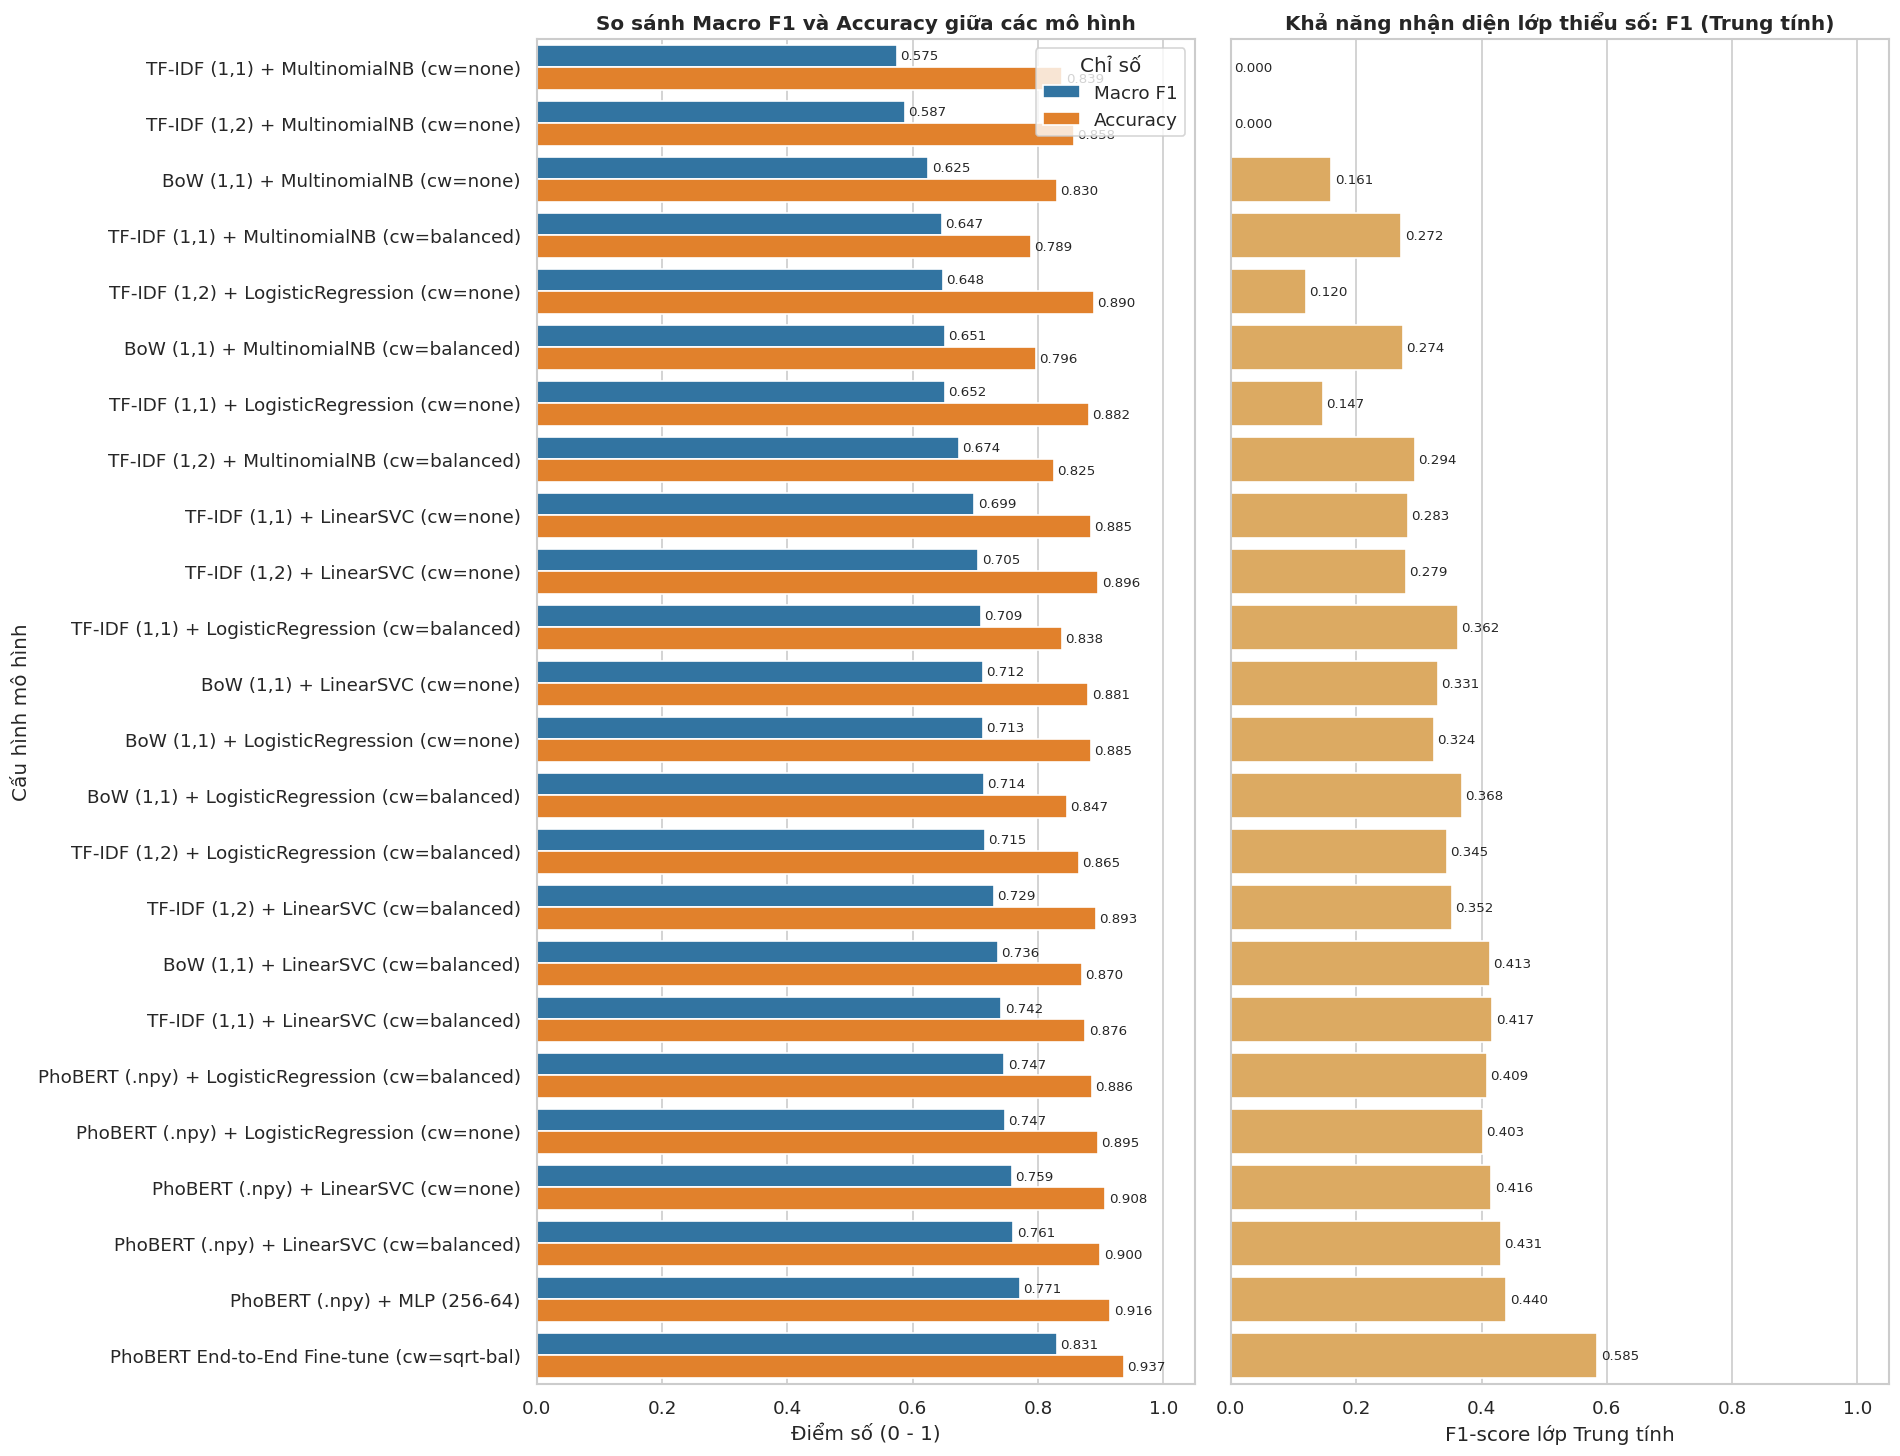

'reports/figures/model_comparison.png'

In [11]:
# Gộp kết quả toàn bộ các mô hình từ Thí nghiệm 2, 3 và 4
exp4_df = pd.DataFrame([exp4_result["metrics"]])
leaderboard_df = pd.concat([exp2_df, exp3_df, exp4_df], ignore_index=True)
leaderboard_df = leaderboard_df.sort_values(by="Macro F1", ascending=False).reset_index(drop=True)

print("=== BẢNG XẾP HẠNG TỔNG HỢP TẤT CẢ MÔ HÌNH ===")
display(leaderboard_df)

os.makedirs("reports", exist_ok=True)
leaderboard_df.to_csv("reports/experiment_results.csv", index=False, encoding="utf-8-sig")
exp1_df.to_csv("reports/ablation_preprocessing.csv", index=False, encoding="utf-8-sig")

plot_model_comparison(
    leaderboard_df,
    metric_col="Macro F1",
    save_path="reports/figures/model_comparison.png",
    show=True,
)

Mô hình tốt nhất toàn cục: PhoBERT End-to-End Fine-tune (cw=sqrt-bal)


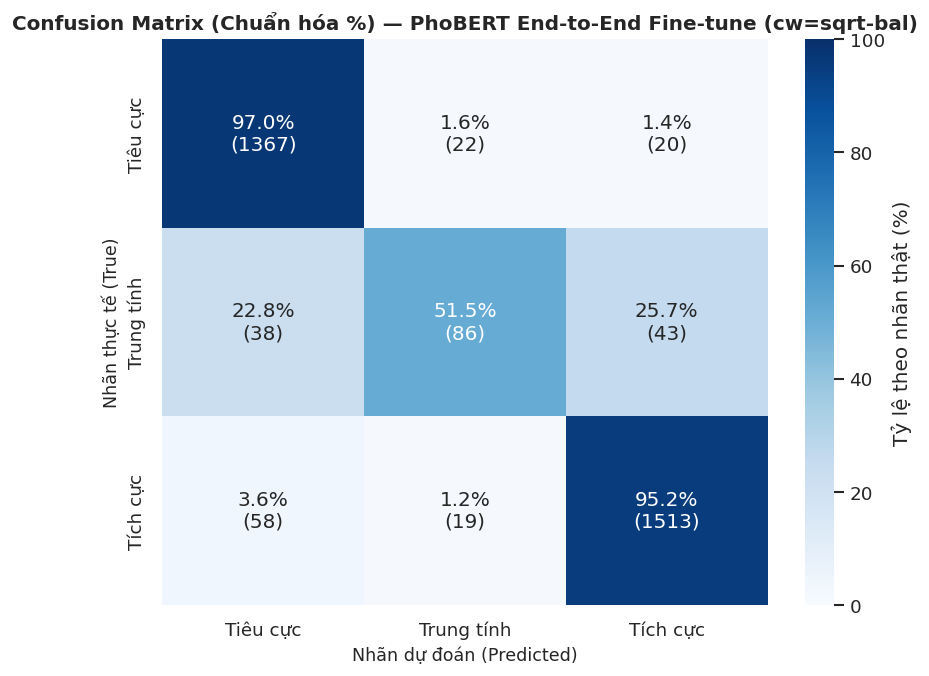

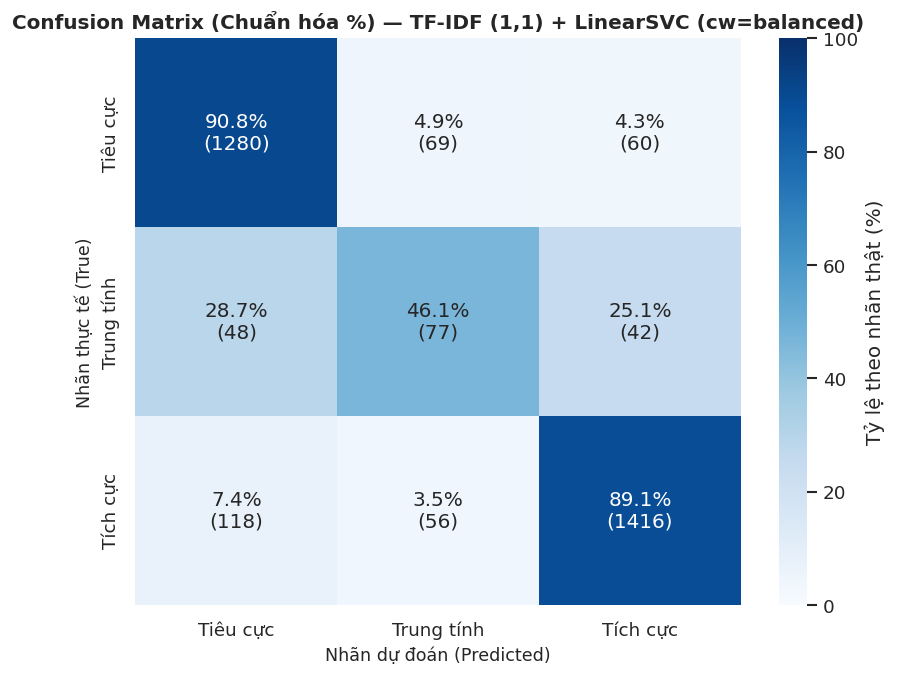

'reports/figures/confusion_matrix_traditional_best.png'

In [12]:
# Vẽ Confusion Matrix cho mô hình tốt nhất và mô hình ML truyền thống tốt nhất
all_predictions = {}
for name, bundle in exp2_artifacts.items():
    all_predictions[name] = (bundle["test_pred"], None)
for name, bundle in exp3_artifacts.items():
    all_predictions[name] = (bundle["test_pred"], bundle.get("test_prob"))
all_predictions[exp4_result["model_name"]] = (exp4_result["test_pred"], exp4_result["test_prob"])

best_overall_name = leaderboard_df.iloc[0]["Mô hình"]
best_test_pred, best_test_prob = all_predictions[best_overall_name]

print(f"Mô hình tốt nhất toàn cục: {best_overall_name}")
plot_confusion_matrix(
    y_test,
    best_test_pred,
    model_name=best_overall_name,
    save_path="reports/figures/confusion_matrix_best.png",
    show=True,
)

plot_confusion_matrix(
    y_test,
    exp2_artifacts[best_trad_name]["test_pred"],
    model_name=best_trad_name,
    save_path="reports/figures/confusion_matrix_traditional_best.png",
    show=True,
)

In [13]:
# Phân tích lỗi (Error Analysis): xuất 15 mẫu dự đoán sai tiêu biểu của mô hình tốt nhất
error_df = perform_error_analysis(
    texts=test_df["text"],
    y_true=y_test,
    y_pred=best_test_pred,
    y_prob=best_test_prob,
    n_samples=15,
    random_state=SEED,
)

total_errors = int((y_test != best_test_pred).sum())
print(f"Tổng số mẫu dự đoán sai trên tập Test: {total_errors}/{len(y_test)} ({total_errors/len(y_test)*100:.2f}%)")
display(error_df)

error_df.to_csv("reports/error_analysis_samples.csv", index=False, encoding="utf-8-sig")

Tổng số mẫu dự đoán sai trên tập Test: 200/3166 (6.32%)


,Index,Văn bản gốc,Nhãn thật,Nhãn dự đoán,Cặp nhầm lẫn,Độ dài (từ),Độ tự tin
0,271,""" các bạn có hiểu ý thầy wzjwz287 không ạ "" ( ...",Tiêu cực,Trung tính,Tiêu cực -> Trung tính,21,0.7754
1,2705,nâng cấp thiết bị phòng lab .,Tiêu cực,Trung tính,Tiêu cực -> Trung tính,7,0.9424
2,2723,em chưa bao giờ được thầy reply mail .,Tiêu cực,Trung tính,Tiêu cực -> Trung tính,9,0.5353
3,1527,"nghiêm khắc trong khi dạy , kiến thức chuyên n...",Tiêu cực,Tích cực,Tiêu cực -> Tích cực,12,0.9849
4,3015,định hướng từ sớm về cách tiếp cận đồ án đối v...,Tiêu cực,Tích cực,Tiêu cực -> Tích cực,15,0.8455
5,585,em nghĩ như vậy sẽ tốt hơn vì họ sẽ biết được ...,Trung tính,Tiêu cực,Trung tính -> Tiêu cực,36,0.9745
6,1450,thêm nhiều bài tập hay .,Trung tính,Tiêu cực,Trung tính -> Tiêu cực,6,0.9736
7,2337,cho bài tập từ dễ tới khó .,Trung tính,Tiêu cực,Trung tính -> Tiêu cực,8,0.9771
8,362,cô cho em 10 điểm thực hành colonlove .,Trung tính,Tích cực,Trung tính -> Tích cực,9,0.8707
9,1447,thầy dạy khá ổn .,Trung tính,Tích cực,Trung tính -> Tích cực,5,0.9486
